# Recorded benchmark performance

Charts of the 119-sentence evaluation already reported in `README.md`: 95 train, 11 validation, 13 test, PhoBERT trained for 10 epochs.

These figures describe that run. They are not a new measurement, and the Llama fertility row still uses `huggyllama/llama-7b`, the tokenizer that produced the published table.

Groups:

- **Tier 1** is the HMM alone.
- **Tier 2** is PhoBERT alone.
- **Tier 3** is Qwen or Llama alone.
- **Two-tier** is HMM, then PhoBERT when the HMM posterior is below 0.85.
- **Three-tier** adds Qwen or Llama when PhoBERT confidence is also below 0.70.
- **Toolkit** is PyVi or Underthesea, included as an external reference.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 160
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

ROOT = Path.cwd()
if not (ROOT / "config.yaml").exists() and (ROOT.parent / "config.yaml").exists():
    ROOT = ROOT.parent
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

GROUP_ORDER = ["Tier 1", "Tier 2", "Tier 3", "Two-tier", "Three-tier", "Toolkit"]
PALETTE = {
    "Tier 1": "#4C78A8",
    "Tier 2": "#F58518",
    "Tier 3": "#54A24B",
    "Two-tier": "#E45756",
    "Three-tier": "#72B7B2",
    "Toolkit": "#B279A2",
}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")
    plt.show()


## Scores

Word-segmentation precision, recall, and F1 count an exact syllable span as a hit. OOV recall restricts that count to gold words absent from the training vocabulary. POS accuracy and POS macro-F1 are measured on the gold segmentation, so every row that uses the PhoBERT tagger shares those two numbers. End-to-end F1 requires both the span and the tag to match.


In [2]:
columns = [
    "model",
    "group",
    "setup",
    "ws_precision",
    "ws_recall",
    "ws_f1",
    "oov_recall",
    "syllable_acc",
    "pos_accuracy",
    "pos_macro_f1",
    "pos_oov_acc",
    "e2e_f1",
]
records = [
    ("HMM", "Tier 1", "HMM only", 63.04, 73.42, 67.84, 32.86, 81.58, 81.43, 63.17, 62.86, 58.48),
    ("PhoBERT", "Tier 2", "PhoBERT only", 81.15, 83.54, 82.33, 68.57, 90.94, 78.90, 42.61, 77.14, 67.78),
    ("Qwen", "Tier 3", "Qwen only", 75.09, 85.23, 79.84, 54.29, 89.47, 78.90, 42.61, 77.14, 62.85),
    ("Llama", "Tier 3", "Llama only", 73.43, 83.97, 78.35, 50.00, 88.89, 78.90, 42.61, 77.14, 61.42),
    ("Hybrid", "Two-tier", "HMM then PhoBERT", 78.19, 80.17, 79.17, 62.86, 89.47, 78.90, 42.61, 77.14, 64.58),
    ("Cascade Qwen", "Three-tier", "HMM, PhoBERT, then Qwen", 80.82, 83.54, 82.16, 68.57, 90.64, 78.90, 42.61, 77.14, 65.98),
    ("Cascade Llama", "Three-tier", "HMM, PhoBERT, then Llama", 80.82, 83.54, 82.16, 68.57, 90.64, 78.90, 42.61, 77.14, 65.98),
    ("Underthesea", "Toolkit", "External toolkit", 68.20, 81.43, 74.23, 54.29, 85.96, 75.95, 60.78, 64.29, 60.77),
    ("PyVi", "Toolkit", "External toolkit", 65.16, 78.90, 71.37, 54.29, 87.28, 79.32, 62.26, 65.71, 56.11),
]
scores = pd.DataFrame(records, columns=columns)
scores["group"] = pd.Categorical(scores["group"], GROUP_ORDER, ordered=True)
scores


,model,group,setup,ws_precision,ws_recall,ws_f1,oov_recall,syllable_acc,pos_accuracy,pos_macro_f1,pos_oov_acc,e2e_f1
0,HMM,Tier 1,HMM only,63.04,73.42,67.84,32.86,81.58,81.43,63.17,62.86,58.48
1,PhoBERT,Tier 2,PhoBERT only,81.15,83.54,82.33,68.57,90.94,78.90,42.61,77.14,67.78
2,Qwen,Tier 3,Qwen only,75.09,85.23,79.84,54.29,89.47,78.90,42.61,77.14,62.85
3,Llama,Tier 3,Llama only,73.43,83.97,78.35,50.00,88.89,78.90,42.61,77.14,61.42
4,Hybrid,Two-tier,HMM then PhoBERT,78.19,80.17,79.17,62.86,89.47,78.90,42.61,77.14,64.58
5,Cascade Qwen,Three-tier,"HMM, PhoBERT, then Qwen",80.82,83.54,82.16,68.57,90.64,78.90,42.61,77.14,65.98
6,Cascade Llama,Three-tier,"HMM, PhoBERT, then Llama",80.82,83.54,82.16,68.57,90.64,78.90,42.61,77.14,65.98
7,Underthesea,Toolkit,External toolkit,68.20,81.43,74.23,54.29,85.96,75.95,60.78,64.29,60.77
8,PyVi,Toolkit,External toolkit,65.16,78.90,71.37,54.29,87.28,79.32,62.26,65.71,56.11


## Word-segmentation F1

PhoBERT alone is the highest single tier. Both three-tier cascades sit 0.17 points under it. The two-tier hybrid, which never calls an LLM, is 3.16 points under PhoBERT. HMM is the lowest segmenter in the set.


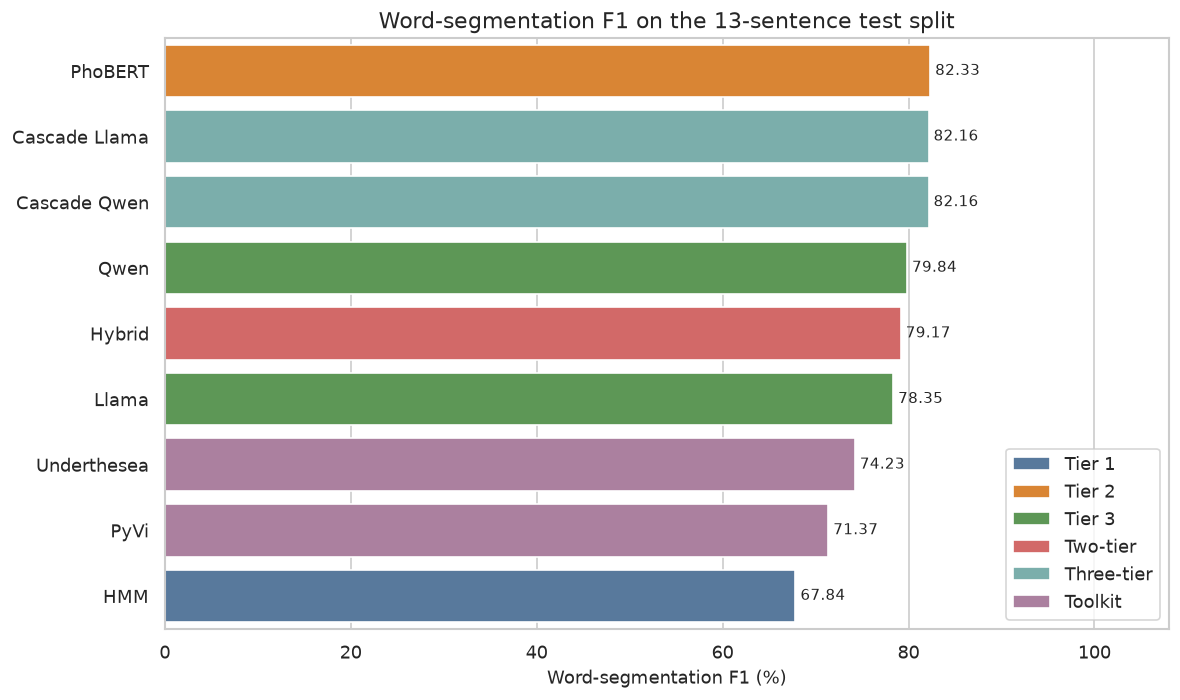

In [3]:
f1_order = scores.sort_values("ws_f1", ascending=False)["model"]
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=scores,
    y="model",
    x="ws_f1",
    hue="group",
    dodge=False,
    order=f1_order,
    hue_order=GROUP_ORDER,
    palette=PALETTE,
    ax=ax,
)
ax.set_xlim(0, 108)
ax.set_xlabel("Word-segmentation F1 (%)")
ax.set_ylabel("")
ax.set_title("Word-segmentation F1 on the 13-sentence test split")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
ax.legend(title="", loc="lower right")
save(fig, "ws_f1.png")


## Precision, recall, and F1

Qwen alone recalls the most gold words and is less precise than PhoBERT. The cascades keep PhoBERT's recall and give up a little precision. HMM is lower on both.


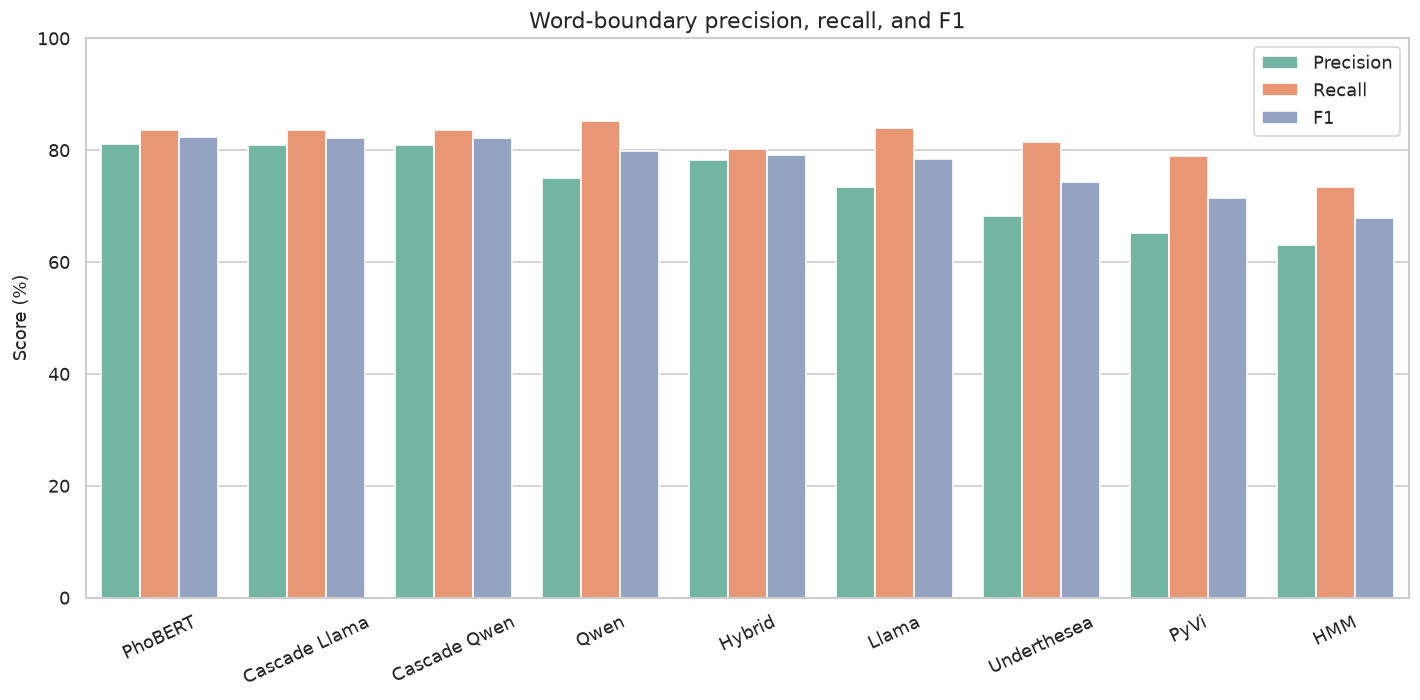

In [4]:
boundary = scores.melt(
    id_vars=["model", "group"],
    value_vars=["ws_precision", "ws_recall", "ws_f1"],
    var_name="metric",
    value_name="score",
)
boundary["metric"] = boundary["metric"].map(
    {"ws_precision": "Precision", "ws_recall": "Recall", "ws_f1": "F1"}
)
metric_order = ["Precision", "Recall", "F1"]
model_order = scores.sort_values("ws_f1", ascending=False)["model"]

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=boundary,
    x="model",
    y="score",
    hue="metric",
    order=model_order,
    hue_order=metric_order,
    palette="Set2",
    ax=ax,
)
ax.set_ylim(0, 100)
ax.set_xlabel("")
ax.set_ylabel("Score (%)")
ax.set_title("Word-boundary precision, recall, and F1")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="")
save(fig, "ws_precision_recall_f1.png")


## Out-of-vocabulary recall

OOV recall counts gold words that never appeared in the 95-sentence training split. PhoBERT and both cascades share 68.57%. HMM recovers 32.86%. On this test split that rate is estimated from about 70 words, so small gaps between the middle systems are unstable.


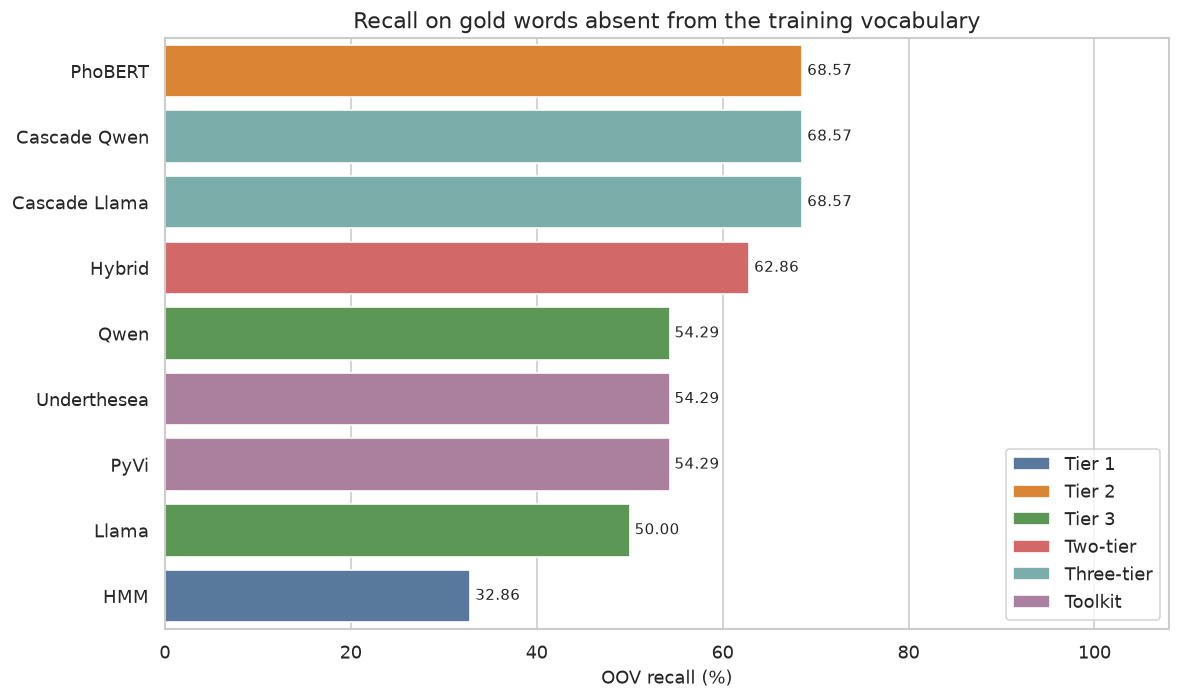

In [5]:
oov_order = scores.sort_values(["oov_recall", "ws_f1"], ascending=False)["model"]
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=scores,
    y="model",
    x="oov_recall",
    hue="group",
    dodge=False,
    order=oov_order,
    hue_order=GROUP_ORDER,
    palette=PALETTE,
    ax=ax,
)
ax.set_xlim(0, 108)
ax.set_xlabel("OOV recall (%)")
ax.set_ylabel("")
ax.set_title("Recall on gold words absent from the training vocabulary")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
ax.legend(title="", loc="lower right")
save(fig, "oov_recall.png")


## Segmentation versus end-to-end tagging

End-to-end F1 requires the syllable span and the POS tag. Systems that share the PhoBERT tagger form a vertical stack: better segmentation lifts the joint score, and the tagger is unchanged. HMM, PyVi, and Underthesea use their own taggers, so they sit off that stack.


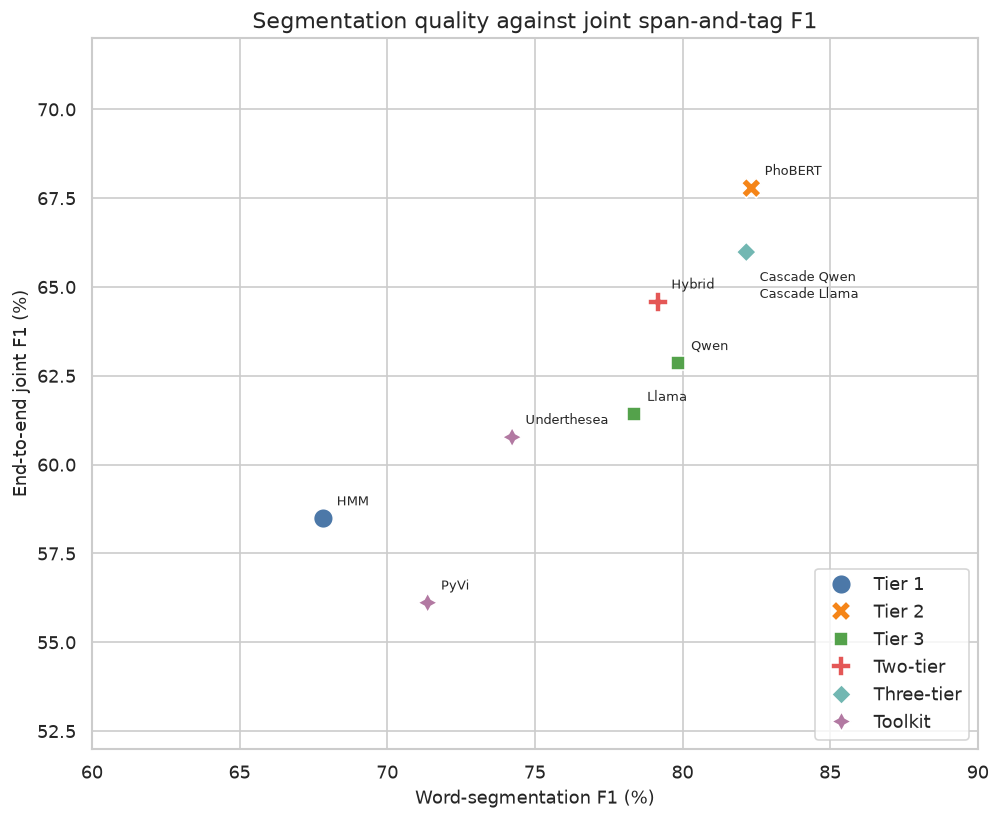

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.scatterplot(
    data=scores,
    x="ws_f1",
    y="e2e_f1",
    hue="group",
    style="group",
    s=140,
    palette=PALETTE,
    ax=ax,
)
labeled = set()
for _, row in scores.iterrows():
    key = (row["ws_f1"], row["e2e_f1"])
    if key in labeled:
        continue
    labeled.add(key)
    names = scores.loc[
        (scores["ws_f1"] == row["ws_f1"]) & (scores["e2e_f1"] == row["e2e_f1"]),
        "model",
    ].tolist()
    # Cascade Qwen and Cascade Llama share one point; stack that label below it.
    below = len(names) > 1
    ax.annotate(
        "\n".join(names),
        (row["ws_f1"], row["e2e_f1"]),
        textcoords="offset points",
        xytext=(8, -10 if below else 6),
        fontsize=8,
        va="top" if below else "bottom",
    )
ax.set_xlim(60, 90)
ax.set_ylim(52, 72)
ax.set_xlabel("Word-segmentation F1 (%)")
ax.set_ylabel("End-to-end joint F1 (%)")
ax.set_title("Segmentation quality against joint span-and-tag F1")
ax.legend(title="", loc="lower right")
save(fig, "ws_vs_e2e.png")


## POS accuracy and macro-F1

Accuracy treats every word equally, so the common tags dominate it. Macro-F1 gives each tag the same weight, so rare VLSP tags pull it down. HMM, PyVi, and Underthesea have the higher macro-F1. The PhoBERT tagger is more even on accuracy and much lower on macro-F1, and every cascade row copies that tagger.


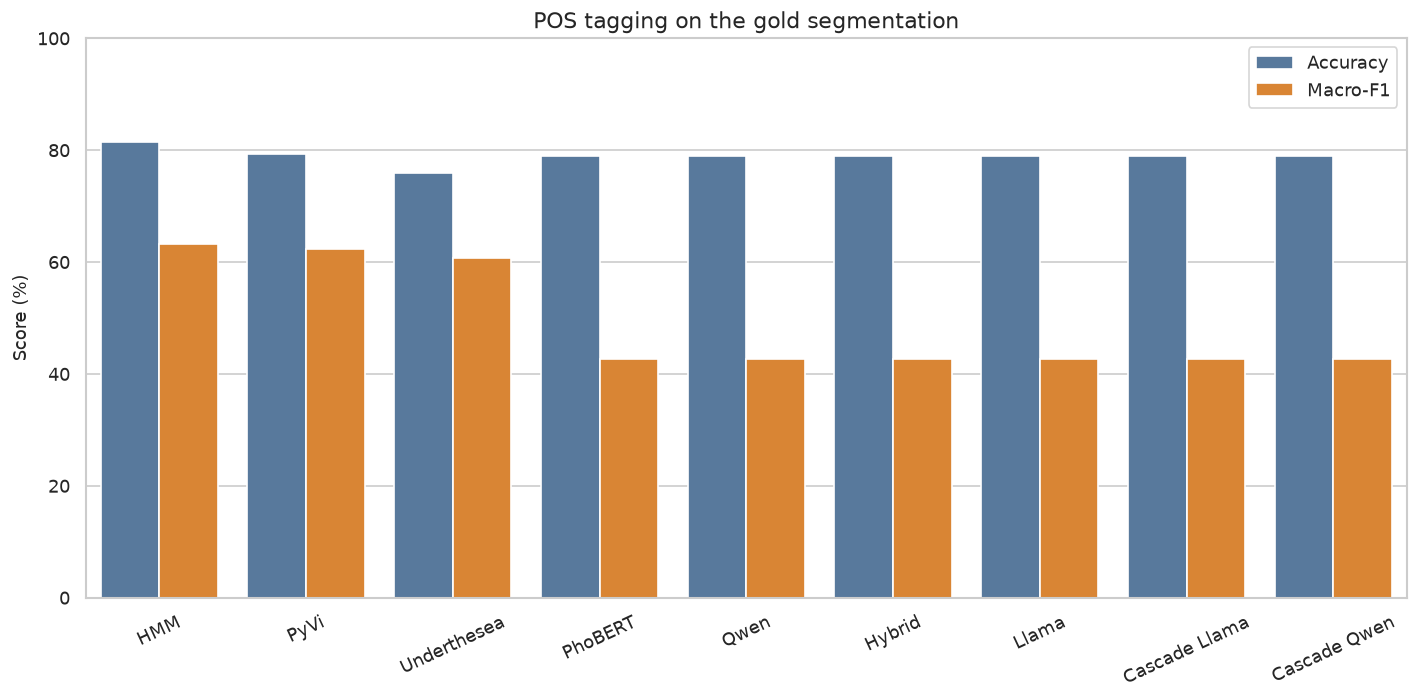

In [7]:
pos = scores.melt(
    id_vars=["model", "group"],
    value_vars=["pos_accuracy", "pos_macro_f1"],
    var_name="metric",
    value_name="score",
)
pos["metric"] = pos["metric"].map(
    {"pos_accuracy": "Accuracy", "pos_macro_f1": "Macro-F1"}
)
pos_order = scores.sort_values("pos_macro_f1", ascending=False)["model"]

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=pos,
    x="model",
    y="score",
    hue="metric",
    order=pos_order,
    hue_order=["Accuracy", "Macro-F1"],
    palette=["#4C78A8", "#F58518"],
    ax=ax,
)
ax.set_ylim(0, 100)
ax.set_xlabel("")
ax.set_ylabel("Score (%)")
ax.set_title("POS tagging on the gold segmentation")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="")
save(fig, "pos_accuracy_macro_f1.png")


## All scores

Each cell is a percent from the same test split. Reading across a row shows where a system is strong. Reading down a column shows who leads that measure.


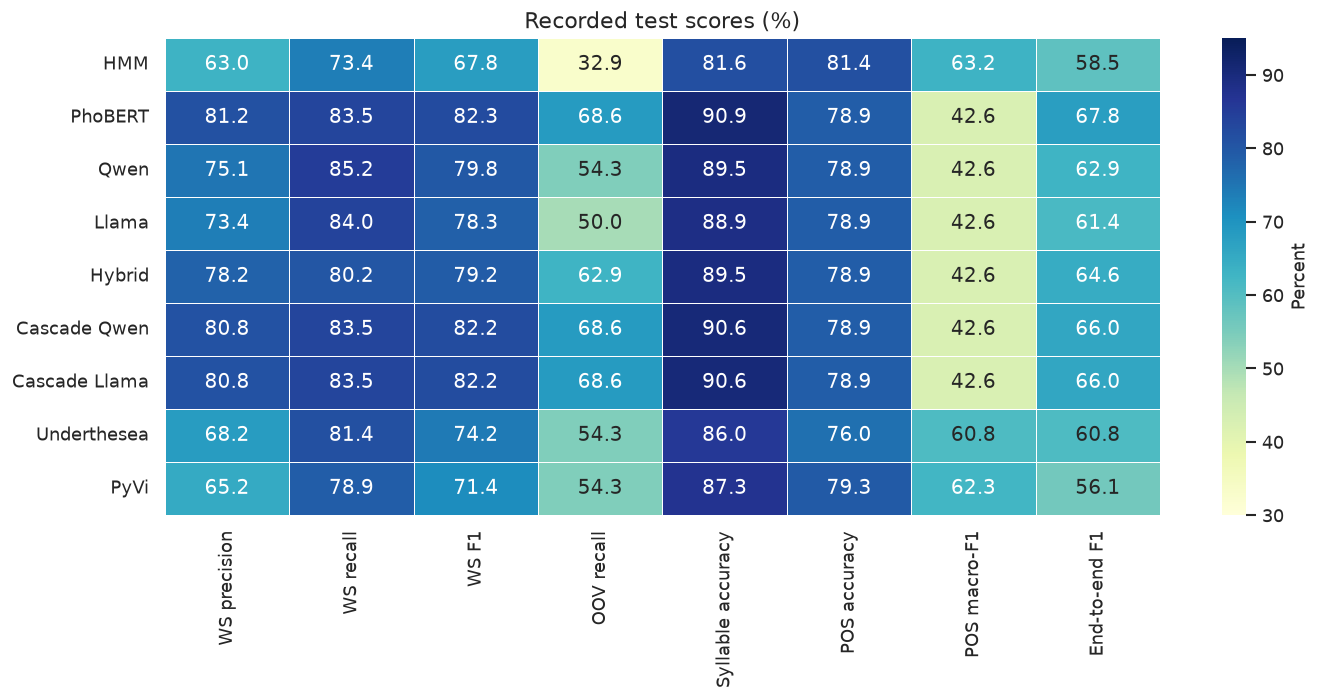

In [8]:
heat_columns = {
    "ws_precision": "WS precision",
    "ws_recall": "WS recall",
    "ws_f1": "WS F1",
    "oov_recall": "OOV recall",
    "syllable_acc": "Syllable accuracy",
    "pos_accuracy": "POS accuracy",
    "pos_macro_f1": "POS macro-F1",
    "e2e_f1": "End-to-end F1",
}
heat = (
    scores.sort_values(["group", "ws_f1"], ascending=[True, False])
    .set_index("model")[list(heat_columns)]
    .rename(columns=heat_columns)
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    heat,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=30,
    vmax=95,
    linewidths=0.4,
    ax=ax,
    cbar_kws={"label": "Percent"},
)
ax.set_title("Recorded test scores (%)")
ax.set_ylabel("")
ax.set_xlabel("")
save(fig, "score_heatmap.png")


## PhoBERT training loss

Word-segmentation validation loss is lowest at epoch 8 and higher at epoch 10, while training loss keeps falling. The 11-sentence validation split is small, and the gap is the overfitting pattern on 95 training sentences. POS validation loss is still falling at epoch 10.


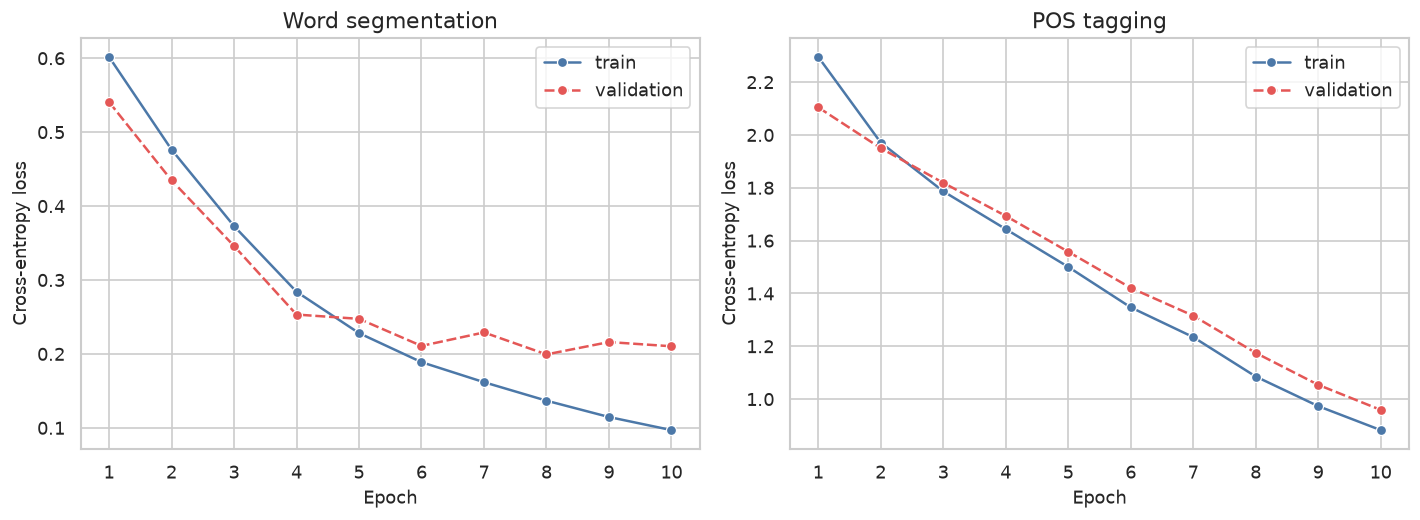

In [9]:
loss = pd.DataFrame(
    {
        "epoch": list(range(1, 11)),
        "WS train": [0.6017, 0.4763, 0.3728, 0.2840, 0.2280, 0.1887, 0.1616, 0.1366, 0.1145, 0.0968],
        "WS validation": [0.5407, 0.4347, 0.3459, 0.2531, 0.2473, 0.2107, 0.2289, 0.1992, 0.2159, 0.2102],
        "POS train": [2.2953, 1.9709, 1.7864, 1.6433, 1.5002, 1.3470, 1.2344, 1.0852, 0.9731, 0.8823],
        "POS validation": [2.1041, 1.9497, 1.8186, 1.6932, 1.5576, 1.4208, 1.3155, 1.1747, 1.0538, 0.9588],
    }
)
long_loss = loss.melt(id_vars="epoch", var_name="curve", value_name="loss")
long_loss["task"] = long_loss["curve"].str.split().str[0]
long_loss["split"] = long_loss["curve"].str.split().str[1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, task, title in zip(axes, ["WS", "POS"], ["Word segmentation", "POS tagging"]):
    part = long_loss[long_loss["task"] == task]
    sns.lineplot(
        data=part,
        x="epoch",
        y="loss",
        hue="split",
        style="split",
        marker="o",
        palette=["#4C78A8", "#E45756"],
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_xticks(range(1, 11))
    ax.legend(title="")
save(fig, "phobert_loss.png")


## Tokenization cost

Subword fertility is the number of model tokens per Vietnamese syllable, measured on all 3,318 syllables in the 119-sentence collection. PhoBERT, trained for Vietnamese, stays near one token per syllable. Qwen is somewhat higher. The published Llama number uses `huggyllama/llama-7b` and is about 2.5 tokens per syllable. The current code points Llama at `meta-llama/Llama-3.2-1B-Instruct`; that fertility has not been remeasured.


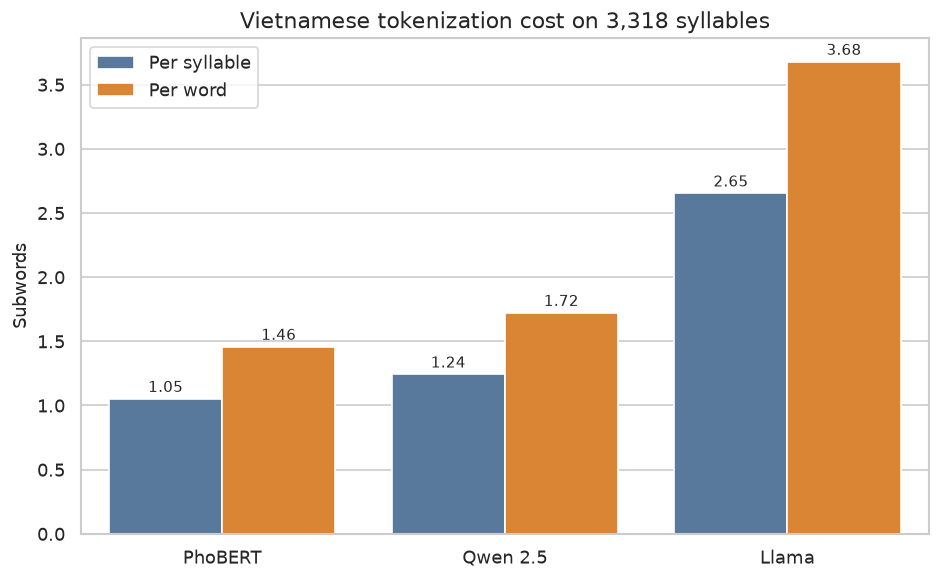

,tokenizer,tokenizer_id,subwords_per_syllable,subwords_per_word,total_subwords
0,PhoBERT,vinai/phobert-base,1.0512,1.4576,3488
1,Qwen 2.5,Qwen/Qwen2.5-1.5B-Instruct,1.2417,1.7217,4120
2,Llama,huggyllama/llama-7b,2.6525,3.6778,8801


In [10]:
fertility = pd.DataFrame(
    {
        "tokenizer": ["PhoBERT", "Qwen 2.5", "Llama"],
        "tokenizer_id": [
            "vinai/phobert-base",
            "Qwen/Qwen2.5-1.5B-Instruct",
            "huggyllama/llama-7b",
        ],
        "subwords_per_syllable": [1.0512, 1.2417, 2.6525],
        "subwords_per_word": [1.4576, 1.7217, 3.6778],
        "total_subwords": [3488, 4120, 8801],
    }
)
fert_long = fertility.melt(
    id_vars=["tokenizer", "tokenizer_id"],
    value_vars=["subwords_per_syllable", "subwords_per_word"],
    var_name="unit",
    value_name="tokens",
)
fert_long["unit"] = fert_long["unit"].map(
    {
        "subwords_per_syllable": "Per syllable",
        "subwords_per_word": "Per word",
    }
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=fert_long,
    x="tokenizer",
    y="tokens",
    hue="unit",
    order=["PhoBERT", "Qwen 2.5", "Llama"],
    hue_order=["Per syllable", "Per word"],
    palette=["#4C78A8", "#F58518"],
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Subwords")
ax.set_title("Vietnamese tokenization cost on 3,318 syllables")
ax.legend(title="")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=9)
save(fig, "tokenization_fertility.png")
fertility
